# Mesh extraction on `fox.npz` (NIQ neural implicit)

End-to-end test of the bucketed `Octree` builder + MC extractor on a pretrained neural implicit surface from `neural-implicit-queries`. Uses `niImplicitSurface` in `affine_fixed` mode for the `classify_box` query.

Sections:
1. Load the surface
2. Tree-build timing across depths 4–8
3. Extract a mesh at depth 7 (MC)
4. 3D visualisation

In [1]:
import os, sys, time
from pathlib import Path
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '7')
#os.environ.setdefault('JAX_PLATFORMS', 'cpu')
sys.path.insert(0, str(Path.cwd().parent))

import jax, jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
import k3d

from implicitSurfaces.niImplicitSurface import niImplicitSurface
from meshExtractor.trees import Octree
from meshExtractor.extractors import MarchingCubes
from meshExtractor import extract_mesh
from meshExtractor.mesh_io import write_obj

print(f'JAX devices: {[d.platform for d in jax.devices()]}')
print(f'k3d version: {k3d.__version__}')

FOX_NPZ = '/system/user/volkmann/neural-implicit-queries/sample_inputs/fox.npz'

JAX devices: ['gpu']
k3d version: 2.17.0


## 1. Load the surface

In [2]:
surface = niImplicitSurface(
    mode='affine_fixed',
    npz_path=FOX_NPZ,
    level_set=0.0,
    dim=3,
)
bounds = (jnp.array([-1.0, -1.0, -1.0]), jnp.array([1.0, 1.0, 1.0]))

Loaded MLP with 7553 params


## 2. Tree-build timing across depths 4–8

Each depth is timed cold (first call) and warm (best of 3). Cold time includes JIT compile of the bucketed `_iter` kernel for any new bucket size encountered at that depth.

In [3]:
results = []
for d in [4, 5, 6, 7, 8]:
    tree = Octree(d)
    t0 = time.time()
    leaves = tree.build(surface, surface.params, *bounds)
    leaves.lower.block_until_ready()
    t_cold = time.time() - t0

    times = [time.time()]
    for _ in range(3):
        leaves = tree.build(surface, surface.params, *bounds)
        leaves.lower.block_until_ready()
        times.append(time.time())
    t_warm = min(b - a for a, b in zip(times, times[1:]))
    n = int(leaves.valid.sum())
    results.append((d, n, t_cold, t_warm))
    print(f'  Octree({d}): cold {t_cold*1000:7.0f} ms | warm {t_warm*1000:7.1f} ms | {n:>7d} UNKNOWN leaves')

E0429 14:39:50.796381 2923179 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


  Octree(4): cold    6226 ms | warm    14.5 ms |    4074 UNKNOWN leaves
  Octree(5): cold    1568 ms | warm    32.2 ms |   29023 UNKNOWN leaves
  Octree(6): cold    1964 ms | warm   133.3 ms |  129332 UNKNOWN leaves
  Octree(7): cold    2654 ms | warm   580.5 ms |  289047 UNKNOWN leaves
  Octree(8): cold    3646 ms | warm  1579.1 ms |  366239 UNKNOWN leaves


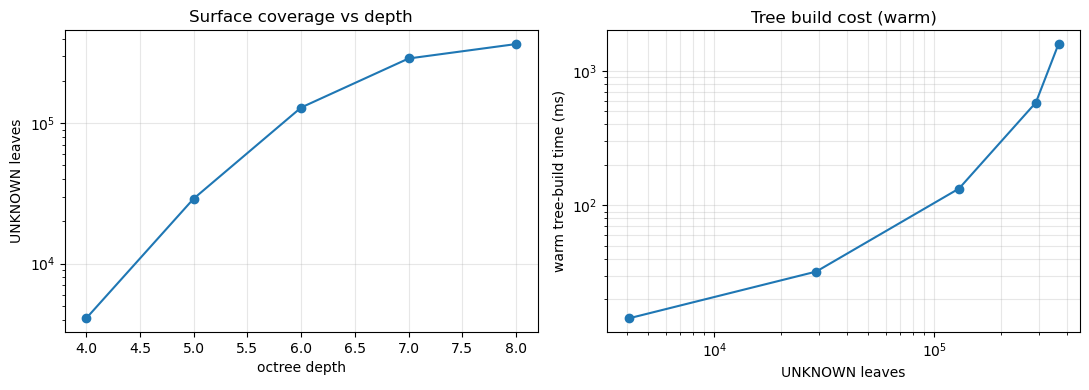

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ds = [r[0] for r in results]
ns = [r[1] for r in results]
tw = [r[3] * 1000 for r in results]
axes[0].plot(ds, ns, 'o-')
axes[0].set_xlabel('octree depth')
axes[0].set_ylabel('UNKNOWN leaves')
axes[0].set_yscale('log')
axes[0].set_title('Surface coverage vs depth')
axes[0].grid(True, alpha=0.3)
axes[1].loglog(ns, tw, 'o-')
axes[1].set_xlabel('UNKNOWN leaves')
axes[1].set_ylabel('warm tree-build time (ms)')
axes[1].set_title('Tree build cost (warm)')
axes[1].grid(True, alpha=0.3, which='both')
plt.tight_layout(); plt.show()

## 3. Extract a mesh at depth 7 with marching cubes

In [5]:
tree = Octree(7)
extractor = MarchingCubes()

t0 = time.time()
verts, tris = extract_mesh(surface, surface.params, bounds, tree, extractor)
verts.block_until_ready()
print(f'  extract_mesh: {time.time()-t0:.2f} s')
print(f'  triangles: {tris.shape[0]}, vertices: {verts.shape[0]}')

v_np = np.asarray(verts).astype(np.float32)
t_np = np.asarray(tris).astype(np.uint32)
print(f'  bbox: {v_np.min(0).round(3).tolist()} → {v_np.max(0).round(3).tolist()}')

out_path = '/tmp/fox_d7.obj'
write_obj(out_path, verts, tris)
print(f'  wrote {out_path}')

  extract_mesh: 3.37 s
  triangles: 28512, vertices: 85536
  bbox: [-0.35899999737739563, -0.8840000033378601, -0.6119999885559082] → [0.2849999964237213, 0.796999990940094, 0.515999972820282]
  wrote /tmp/fox_d7.obj


## 4. 3D visualisation with k3d

Interactive WebGL viewer. Drag to orbit, scroll to zoom, right-click drag to pan.

Per-vertex normals are computed by averaging incident face normals, so MC's faceted look is replaced with smooth shading.

In [6]:
def vertex_normals(v_np: np.ndarray, t_np: np.ndarray) -> np.ndarray:
    """Average incident face normals at each vertex."""
    tri_v = v_np[t_np]
    face_n = np.cross(tri_v[:, 1] - tri_v[:, 0], tri_v[:, 2] - tri_v[:, 0])
    face_n /= np.maximum(np.linalg.norm(face_n, axis=1, keepdims=True), 1e-12)
    n = np.zeros_like(v_np)
    for k in range(3):
        np.add.at(n, t_np[:, k], face_n)
    n /= np.maximum(np.linalg.norm(n, axis=1, keepdims=True), 1e-12)
    return n.astype(np.float32)

v_norm = vertex_normals(v_np, t_np)
print(f'normals: {v_norm.shape}')

normals: (85536, 3)


In [7]:
plot = k3d.plot(camera_auto_fit=True, grid_visible=False, background_color=0xf5f5f5)
mesh = k3d.mesh(
    vertices=v_np,
    indices=t_np,
    normals=v_norm,
    color=0xc8966a,
    flat_shading=False,
    name='fox',
)
plot += mesh
plot.display()

Output()